---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group 17 (DerbyCounty)

- Juan Oloando Simanungkalit (13524032) - juanoloando.s@gmail.com
- Nashiruddin Akram (13524090) - akrambaasir@gmail.com
- Reinsen Silitonga (13524093) - reinsilitonga12@gmail.com
- Arghawisesa Dwinanda Arham (13524100) - arghaku.argha@gmail.com
- Manuel Thimoty Silalahi (13524102) - manuelsilalahi06@gmail.com

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)

12. [**Referensi**](#references)
13. [**Bonus Naive Bayes**](#12)

---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

Penyelenggara penginapan ingin memprediksi apakah sebuah pemesanan akan dibatalkan (`is_canceled`) dari data pemesanan seperti lead time, jumlah malam, harga, kanal pemesanan, dan permintaan khusus.

## Aim

Membangun model klasifikasi biner from scratch yang memaksimalkan Macro F1 pada data test Kaggle, dengan pipeline yang reproducible.

## Metric

Macro F1 = rata-rata F1 kelas 0 dan F1 kelas 1. Kedua kelas berbobot sama, jadi model tidak cukup hanya bagus di kelas mayoritas.

## Dataset

`train.csv` berisi 27.373 baris dengan 17 fitur dan label, `test.csv` berisi 6.844 baris tanpa label. Ada missing value, duplikat, dan nilai tidak valid.

## Approach

Eksperimen kedua mempertahankan preprocessing baseline 17 fitur dan memakai lima fold stratified yang sama. Pencarian mengubah alpha, yaitu smoothing probabilitas kategori, bobot kontribusi lead time dan permintaan khusus, serta threshold keputusan. Hasil baseline lama tetap bisa direproduksi dari notebook pertama.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [1]:
# %pip install -q numpy pandas matplotlib scikit-learn

## Import Libraries

Every import of the notebook is kept in this cell.

In [2]:
import hashlib
import os
import pickle
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.naive_bayes import CategoricalNB

## Settings

Paths and shared constants are kept in this class.

In [3]:
def find_data_dir():
    override = os.environ.get('DERBY_DATA_DIR')
    if override:
        return Path(override).expanduser()
    here = Path.cwd()
    candidates = [folder / 'data' for folder in (here, *here.parents)]
    candidates.append(Path.home() / 'Documents/GitHub/IF3170_G17_DerbyCounty/data')
    return next((folder for folder in candidates if (folder / 'train.csv').is_file()), candidates[0])


def find_output_dir():
    here = Path.cwd()
    root = next((folder for folder in (here, *here.parents)
                 if (folder / 'src').is_dir() and (folder / 'data').is_dir()), here)
    return Path(os.environ.get('DERBY_OUTPUT_DIR', root / 'output' / 'template_nb'))


class Settings:
    SEED       = 42
    ID_COLUMN  = 'id'
    TARGET     = 'is_canceled'
    N_FOLDS    = 5
    FEATURES   = None
    BASELINE_ALPHA = 1.0
    ALPHAS = (1.0, 0.01, 0.03, 0.1, 0.3, 0.5, 2.0, 3.0, 5.0, 10.0, 30.0, 100.0)
    WEIGHTS    = (1.0, 0.5, 0.75, 1.25, 1.5, 2.0)
    DATA_DIR   = find_data_dir()
    OUTPUT_DIR = find_output_dir()
    EXP_NAME   = 'nb_baseline_finetune'
    MODEL_PATH = OUTPUT_DIR / 'models' / f'{EXP_NAME}.pkl'
    SUB_PATH   = OUTPUT_DIR / 'submissions' / f'submission_{EXP_NAME}.csv'
    BONUS_PATH = OUTPUT_DIR / 'figures' / f'bonus_{EXP_NAME}.png'


CFG = Settings()
ID_COL, TARGET = CFG.ID_COLUMN, CFG.TARGET

`DATA_DIR` harus berisi `train.csv`, `test.csv`, dan `sample_submission.csv`. Atur `DERBY_DATA_DIR` sebelum menjalankan notebook jika data berada di folder lain. Eksperimen memakai seed 42, lima fold, dan 17 fitur asli. Alpha 1 menjadi pembanding baseline.

## Seed Everything

A fixed seed keeps the results reproducible.

In [4]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [5]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={ID_COL: str})
test_df = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={ID_COL: str})
sample = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv', dtype={ID_COL: str})
print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [6]:
def types(df):
    kinds = ['numeric' if pd.api.types.is_numeric_dtype(df[column]) else 'categorical' for column in df]
    return pd.DataFrame({'dtype': df.dtypes.astype(str), 'kind': kinds, 'unique': df.nunique()})

In [7]:
types(train_df)

,dtype,kind,unique
id,str,categorical,27373
num_adults,float64,numeric,5
num_children,float64,numeric,6
weekend_nights,int64,numeric,8
weekday_nights,int64,numeric,18
meal_package,str,categorical,4
needs_parking,float64,numeric,2
room_category,str,categorical,7
days_before_arrival,float64,numeric,407
arrival_year,int64,numeric,2


In [8]:
train_df.describe()

,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,26564.000000,24338.000000,27373.000000,27373.000000,26291.000000,26250.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,2.533500e+04,24873.000000,27373.000000
mean,1.845242,0.117388,0.814854,2.206517,0.030200,85.379429,2023.820115,7.399664,15.537537,0.025171,0.021883,0.144887,1.716980e+06,0.666948,0.327659
std,0.517974,0.425761,0.875146,1.421603,0.171142,85.969638,0.384099,3.074788,8.773321,0.156646,0.356353,1.693652,5.879368e+05,0.798363,0.469368
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2023.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2024.000000,5.000000,8.000000,0.000000,0.000000,0.000000,1.338000e+06,0.000000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,58.000000,2024.000000,8.000000,16.000000,0.000000,0.000000,0.000000,1.644000e+06,0.000000,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,126.000000,2024.000000,10.000000,23.000000,0.000000,0.000000,0.000000,2.019000e+06,1.000000,1.000000
max,4.000000,10.000000,7.000000,17.000000,1.000000,448.000000,2024.000000,12.000000,31.000000,1.000000,13.000000,58.000000,9.165000e+06,5.000000,1.000000


Arti tiap kolom:

| Kolom | Arti |
|---|---|
| `num_adults`, `num_children` | jumlah tamu dewasa dan anak |
| `weekend_nights`, `weekday_nights` | jumlah malam akhir pekan dan hari kerja |
| `meal_package` | paket makan (Room Only, Breakfast, Half Board, Full Board) |
| `needs_parking` | butuh tempat parkir (0/1) |
| `room_category` | tipe kamar (Type A sampai G) |
| `days_before_arrival` | lead time, jarak hari antara pemesanan dan kedatangan |
| `arrival_year`, `arrival_month`, `arrival_day` | tanggal kedatangan |
| `booking_channel` | kanal pemesanan (Online Travel Agent, Offline Agent, Corporate, Complimentary, Airline) |
| `is_returning_guest` | tamu yang pernah menginap (0/1) |
| `prior_cancellations`, `prior_completed_bookings` | riwayat pembatalan dan pemesanan selesai |
| `nightly_rate_idr` | harga per malam dalam rupiah |
| `special_requests` | jumlah permintaan khusus |
| `is_canceled` | target, 1 kalau pemesanan dibatalkan |

#### Insights

- Data berisi 27.373 baris, 13 kolom numerik dan 3 kolom kategorikal (`meal_package`, `room_category`, `booking_channel`).
- Lead time sangat menceng ke kanan: median 58 hari, tetapi maksimum 448 hari.
- Harga per malam bermedian sekitar Rp1,64 juta dengan maksimum Rp9,17 juta, dan ada 413 baris berharga 0.
- Kedatangan hanya di tahun 2023 (4.924 baris) dan 2024 (22.449 baris).
- Rentang nilai antarkolom sangat berbeda (harga jutaan, jumlah malam satuan), jadi model berbasis jarak wajib memakai scaling.

## Explore Data

This part covers distributions and relationships between attributes.

In [9]:
def target_rate(df, columns, bins=None):
    figure, axes = plt.subplots(1, len(columns), figsize=(5 * len(columns), 3.5))
    for axis, column in zip(axes, columns):
        values = pd.qcut(df[column], bins[column], duplicates='drop') if bins and column in bins else df[column]
        df.groupby(values, observed=True)[CFG.TARGET].mean().plot.bar(ax=axis)
        axis.set_title(column)
        axis.set_ylabel(f'rate {CFG.TARGET}')
    plt.tight_layout()
    plt.show()

is_canceled
0    0.672
1    0.328
Name: proportion, dtype: float64


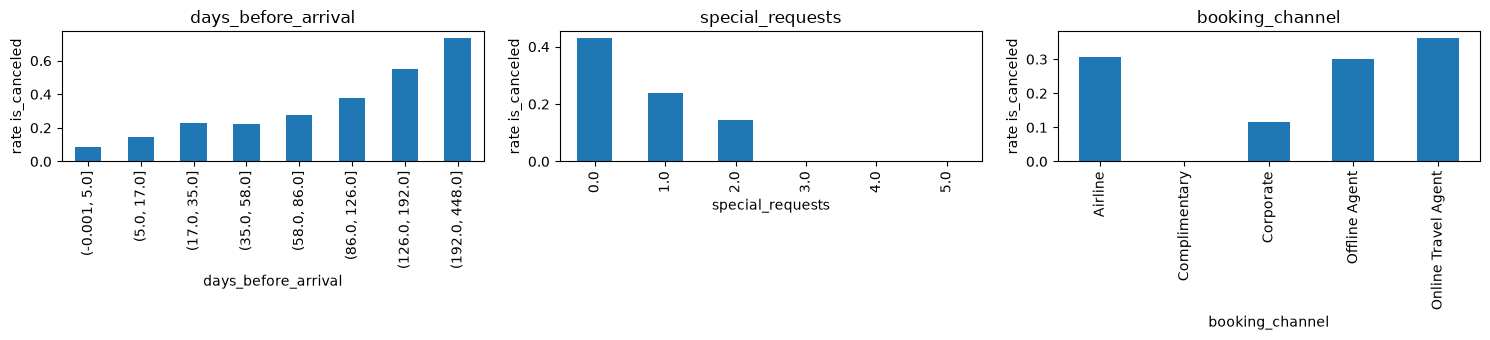

In [10]:
print(train_df[CFG.TARGET].value_counts(normalize=True).round(3))
target_rate(train_df, ['days_before_arrival', 'special_requests', 'booking_channel'], bins={'days_before_arrival': 8})

#### Insights

- Kelas tidak seimbang ringan, sekitar 33% batal. Macro F1 memberi bobot sama ke dua kelas, jadi threshold perlu ditentukan, bukan selalu 0.5.
- Lead time (`days_before_arrival`) dan `special_requests` paling kuat memisahkan kelas: booking jauh hari makin sering batal, tamu dengan permintaan khusus jarang batal. Dua fitur ini nanti diberi bobot 2 di jarak KNN.

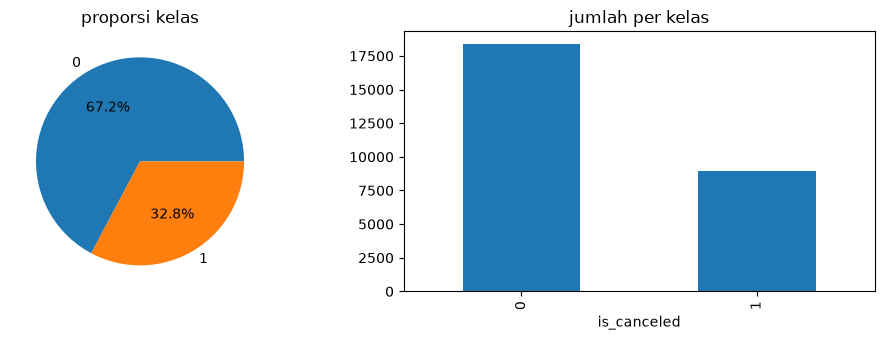

In [11]:
figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))
train_df[CFG.TARGET].value_counts().plot.pie(ax=axes[0], autopct='%.1f%%', ylabel='', title='proporsi kelas')
train_df[CFG.TARGET].value_counts().plot.bar(ax=axes[1], title='jumlah per kelas')
plt.tight_layout()
plt.show()

Distribusi fitur numerik dipisah per kelas. `density=True` supaya dua kelas yang jumlahnya beda tetap bisa dibandingkan.

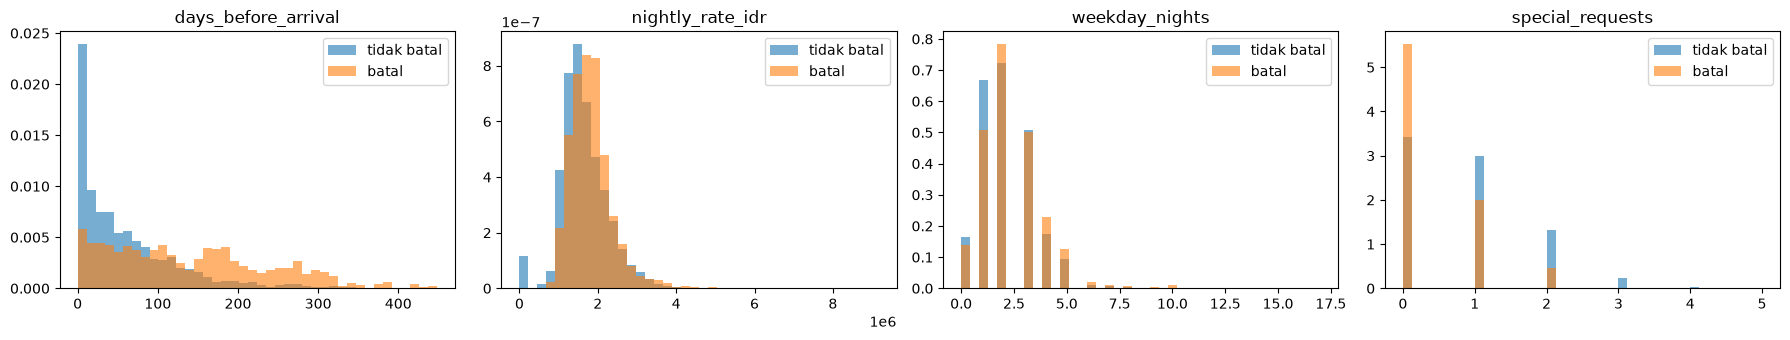

In [12]:
def histogram_by_target(df, columns, bins=40):
    figure, axes = plt.subplots(1, len(columns), figsize=(4.5 * len(columns), 3.5))
    for axis, column in zip(axes, columns):
        edges = np.histogram_bin_edges(df[column].dropna(), bins=bins)
        for label, name in [(0, 'tidak batal'), (1, 'batal')]:
            axis.hist(df.loc[df[CFG.TARGET] == label, column].dropna(), bins=edges, alpha=0.6, density=True, label=name)
        axis.set_title(column)
        axis.legend()
    plt.tight_layout()
    plt.show()

histogram_by_target(train_df, ['days_before_arrival', 'nightly_rate_idr', 'weekday_nights', 'special_requests'])

#### Insights

- Distribusi lead time kelas batal jauh lebih ke kanan. Rasio batal naik dari 8,8% (lead 0 sampai 5 hari) menjadi 73,8% (lead di atas 192 hari).
- Rasio batal naik seiring harga, dari 20,6% di kuintil termurah ke 44,5% di kuintil keempat, lalu turun sedikit di kuintil termahal (36,1%).
- Menginap lebih dari 10 malam punya rasio batal 68,7%, jauh di atas rata-rata.
- Tamu tanpa permintaan khusus batal 43,2%, dengan 1 permintaan 23,8%, dan dengan 3 atau lebih hampir tidak pernah batal.

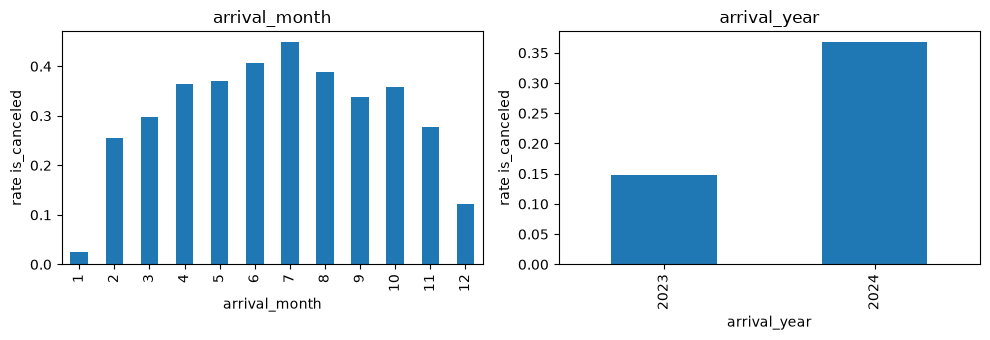

In [13]:
target_rate(train_df, ['arrival_month', 'arrival_year'])

#### Insights

- Ada pola musiman kuat: rasio batal terendah di Januari (2,6%) dan Desember (12,1%), tertinggi di Juli (44,8%).
- Korelasi linear `arrival_month` dengan target hampir 0 (-0,016) karena polanya naik lalu turun. Pola melingkar ini ditangkap oleh `month_cos`, yang membuat Desember dan Januari berdekatan.
- Tahun 2023 hanya 14,7% batal, sedangkan 2024 36,7%. `arrival_year` tidak dipakai langsung karena hanya 2 nilai dan sebagian besar efeknya sudah tertangkap lewat `booking_index`.

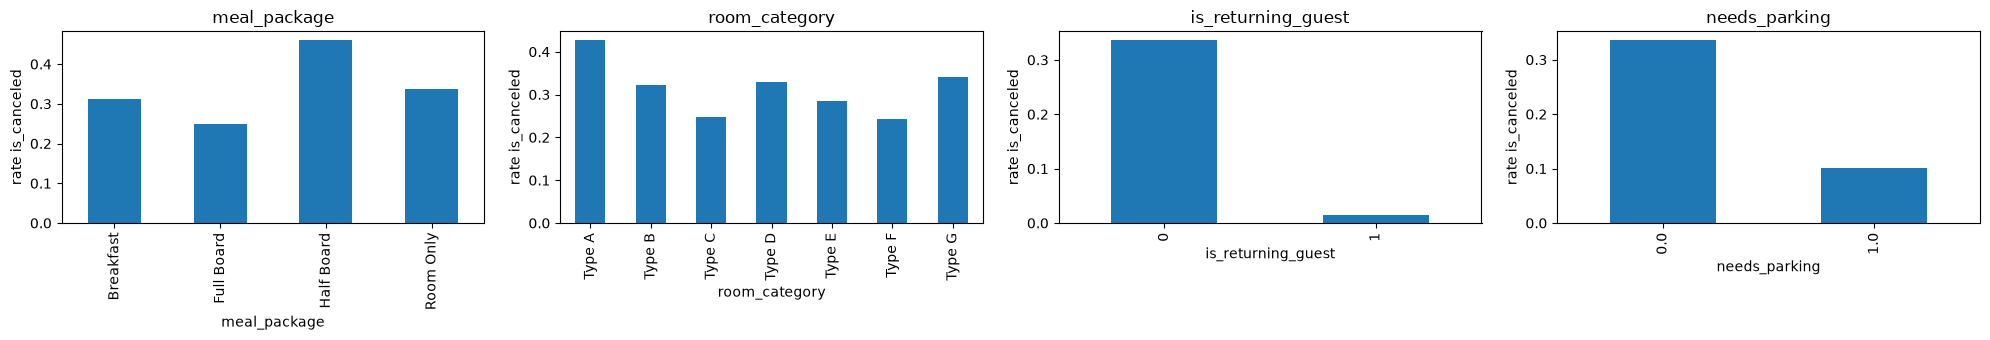

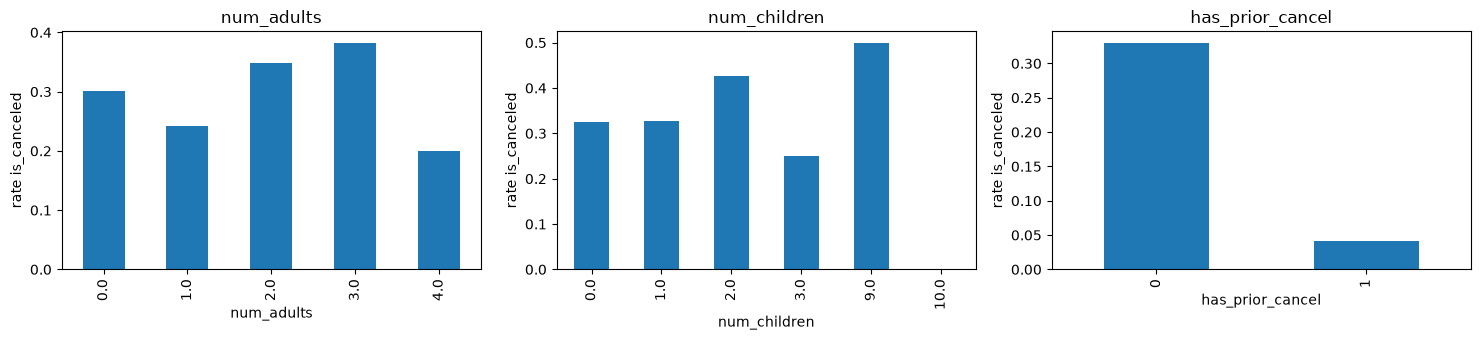

In [14]:
target_rate(train_df, ['meal_package', 'room_category', 'is_returning_guest', 'needs_parking'])
target_rate(train_df.assign(has_prior_cancel=(train_df['prior_cancellations'] > 0).astype(int)),
            ['num_adults', 'num_children', 'has_prior_cancel'])

#### Insights

- Kanal pemesanan sangat berpengaruh: Complimentary 0%, Corporate 11,5%, Offline Agent 30,2%, Online Travel Agent 36,4%.
- Tamu yang pernah menginap hampir tidak pernah batal (1,5% dibanding 33,6%). Tamu yang butuh parkir juga jarang batal (10,1% dibanding 33,5%).
- Paket Half Board paling sering batal (45,9%), sedangkan Full Board hanya 4 baris sehingga tidak bisa disimpulkan.
- Tamu dengan riwayat pembatalan justru jarang batal lagi, tetapi jumlahnya sangat sedikit (sekitar 1%).
- Beberapa kategori sangat jarang (Full Board 4 baris, Type E 7 baris, num_children 9 dan 10). Untuk KNN ini tidak masalah karena kategori jarang hanya menambah jarak.

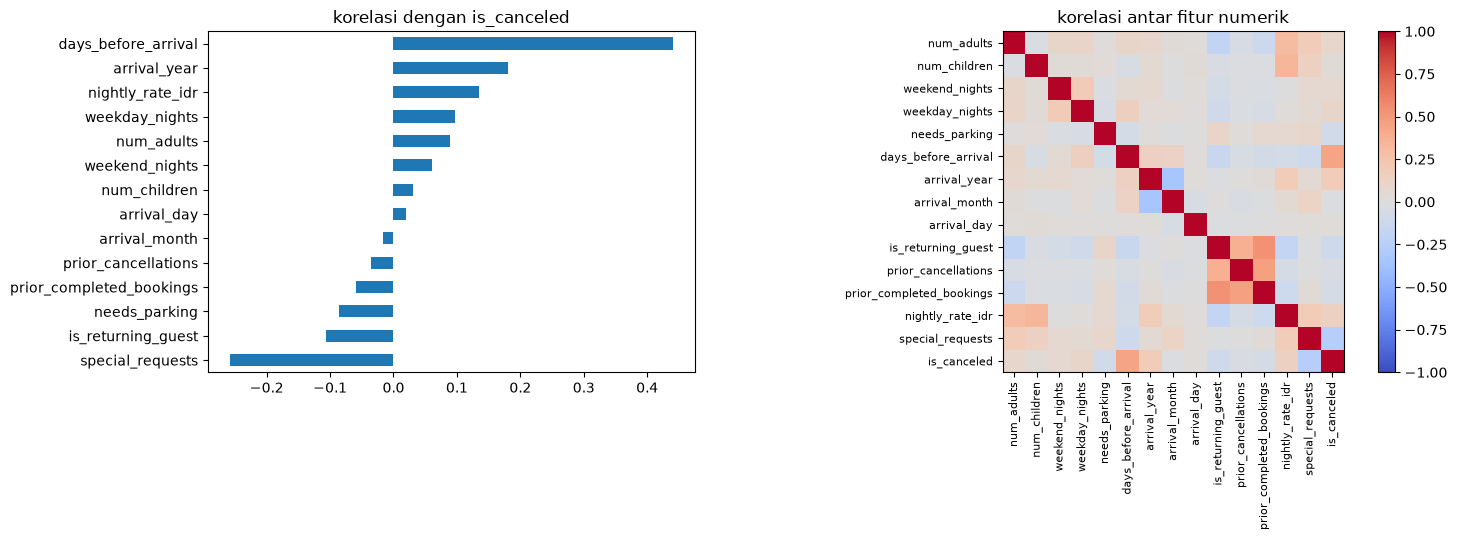

In [15]:
corr = train_df.select_dtypes('number').corr()
figure, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1, 1.4]})
corr[CFG.TARGET].drop(CFG.TARGET).sort_values().plot.barh(ax=axes[0], title='korelasi dengan is_canceled')
image = axes[1].imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
axes[1].set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
axes[1].set_yticks(range(len(corr)), corr.columns, fontsize=8)
axes[1].set_title('korelasi antar fitur numerik')
figure.colorbar(image, ax=axes[1])
plt.tight_layout()
plt.show()

#### Insights

- Korelasi terkuat dengan target: lead time (0,44), special_requests (-0,26), arrival_year (0,18), nightly_rate_idr (0,13), is_returning_guest (-0,11).
- Korelasi antarfitur rendah. Pasangan tertinggi hanya is_returning_guest dengan prior_completed_bookings (0,53), jadi tidak ada fitur yang benar-benar duplikat.
- Korelasi hanya menangkap hubungan linear. Bulan kedatangan berkorelasi hampir 0 tetapi polanya kuat (grafik musiman di atas), jadi seleksi fitur tidak boleh hanya berdasarkan korelasi.

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [16]:
def missing(train, test):
    features = test.columns.drop(CFG.ID_COLUMN)
    table = pd.DataFrame({'train': train[features].isna().mean() * 100,
                          'test': test[features].isna().mean() * 100}).round(2)
    return table[table.sum(axis=1) > 0]

def duplicates(df):
    features = df.columns.drop([CFG.ID_COLUMN, CFG.TARGET])
    labels = df.groupby(list(features), dropna=False)[CFG.TARGET].nunique()
    return pd.Series({'baris duplikat': df.duplicated(subset=list(features) + [CFG.TARGET]).sum(),
                      'fitur sama, label beda': (labels > 1).sum()})

In [17]:
missing(train_df, test_df)

,train,test
num_adults,2.96,2.63
num_children,11.09,10.91
meal_package,6.43,6.46
needs_parking,3.95,3.61
room_category,3.66,3.54
days_before_arrival,4.10,4.24
nightly_rate_idr,7.45,7.89
special_requests,9.13,8.66


In [18]:
print(duplicates(train_df))
print('num_adults = 0:', (train_df['num_adults'] == 0).sum())

baris duplikat            64
fitur sama, label beda     2
dtype: int64
num_adults = 0: 106


#### Insights

Nilai kosong muncul pada kedua berkas. Preprocessor baseline menyimpannya sebagai kategori khusus. Data train mengandung duplikat dan baris dengan `num_adults = 0`.

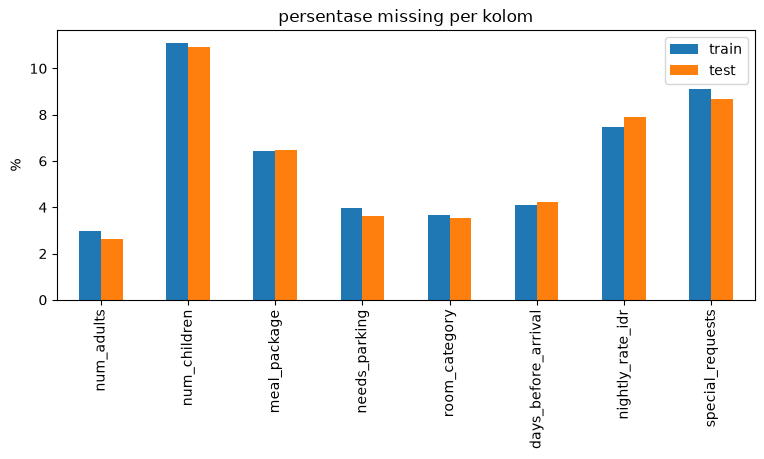

In [19]:
missing(train_df, test_df).plot.bar(figsize=(9, 3.5), title='persentase missing per kolom')
plt.ylabel('%')
plt.show()

Apakah baris yang missing punya rasio batal berbeda? Kalau berbeda, missing itu sendiri membawa informasi.

In [20]:
missing_cols = train_df.columns[train_df.isna().any()]
pd.DataFrame({'rasio batal jika missing': [train_df.loc[train_df[c].isna(), CFG.TARGET].mean() for c in missing_cols],
              'rasio batal jika terisi': [train_df.loc[train_df[c].notna(), CFG.TARGET].mean() for c in missing_cols]},
             index=missing_cols).round(3)

,rasio batal jika missing,rasio batal jika terisi
num_adults,0.335,0.327
num_children,0.328,0.328
meal_package,0.319,0.328
needs_parking,0.312,0.328
room_category,0.348,0.327
days_before_arrival,0.312,0.328
nightly_rate_idr,0.313,0.329
special_requests,0.408,0.320


Pengecekan nilai yang tidak masuk akal.

In [21]:
nights = train_df['weekend_nights'] + train_df['weekday_nights']
pd.Series({'num_adults = 0': (train_df['num_adults'] == 0).sum(),
           'total malam = 0': (nights == 0).sum(),
           'num_children >= 9': (train_df['num_children'] >= 9).sum(),
           'harga 0 bukan Complimentary': ((train_df['nightly_rate_idr'] == 0) & (train_df['booking_channel'] != 'Complimentary')).sum()},
          name='jumlah baris')

num_adults = 0                 106
total malam = 0                 64
num_children >= 9                3
harga 0 bukan Complimentary    146
Name: jumlah baris, dtype: int64

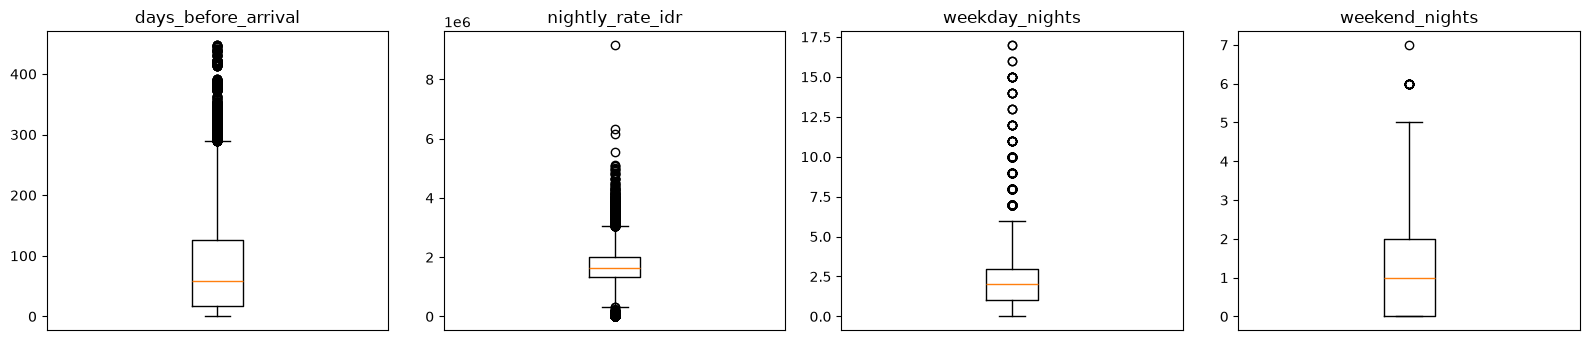

In [22]:
outlier_cols = ['days_before_arrival', 'nightly_rate_idr', 'weekday_nights', 'weekend_nights']
figure, axes = plt.subplots(1, len(outlier_cols), figsize=(4 * len(outlier_cols), 3.5))
for axis, column in zip(axes, outlier_cols):
    axis.boxplot(train_df[column].dropna())
    axis.set_title(column)
    axis.set_xticks([])
plt.tight_layout()
plt.show()

#### Insights

Untuk mempertahankan prediksi baseline, pencilan dibiarkan utuh dan nilai `num_adults = 0` ditandai sebagai missing.

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [23]:
def clean_train(df):
    feature_cols = [c for c in df.columns if c != ID_COL]
    return df.drop_duplicates(subset=feature_cols).reset_index(drop=True)


def stratified_kfold(y, n_splits=5, seed=42):
    y = np.asarray(y)
    rng = np.random.RandomState(seed)
    fold_of = np.empty(len(y), dtype=int)
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        fold_of[idx] = np.arange(len(idx)) % n_splits
    return [(np.where(fold_of != k)[0], np.where(fold_of == k)[0]) for k in range(n_splits)]



# Duplikat persis dibuang dari train sebelum membuat fold.
train = clean_train(train_df)
y = train[TARGET].to_numpy()
folds = stratified_kfold(y, CFG.N_FOLDS, CFG.SEED)
print('sebelum', train_df.shape, 'sesudah', train.shape)

sebelum (27373, 19) sesudah (27309, 19)


In [24]:
pd.DataFrame([
    {'fold': i, 'baris latih': len(fit), 'baris validasi': len(valid),
     'proporsi batal validasi': y[valid].mean()}
    for i, (fit, valid) in enumerate(folds, 1)
]).round(4)

,fold,baris latih,baris validasi,proporsi batal validasi
0,1,21847,5462,0.3275
1,2,21847,5462,0.3275
2,3,21847,5462,0.3275
3,4,21847,5462,0.3275
4,5,21848,5461,0.3274


#### Insights

Setiap baris train menjadi data validasi tepat sekali. Jumlah pemesanan batal dibuat seimbang secara proporsional antarfold. Data test terpisah dari pembagian ini.

---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [25]:
features = train.columns.drop([ID_COL, TARGET]).tolist()
print(len(features), 'fitur asli')
features

17 fitur asli


['num_adults',
 'num_children',
 'weekend_nights',
 'weekday_nights',
 'meal_package',
 'needs_parking',
 'room_category',
 'days_before_arrival',
 'arrival_year',
 'arrival_month',
 'arrival_day',
 'booking_channel',
 'is_returning_guest',
 'prior_cancellations',
 'prior_completed_bookings',
 'nightly_rate_idr',
 'special_requests']

#### Insights

Semua 17 fitur asli dipakai. ID berfungsi sebagai identitas submission, dan target dipisah sebagai label.

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

Nilai kosong dikodekan sebagai kategori khusus. Kode 0 disediakan untuk kategori baru atau langka, dan kode 1 untuk nilai kosong.

### Duplicates

This part covers repeated records.

In [26]:
print('duplikat train dibuang', len(train_df) - len(train))

duplikat train dibuang 64


Deduplikasi dilakukan sebelum pembagian fold menggunakan semua fitur dan target dengan mengabaikan ID.

### Outliers

This part covers values far from the rest of the data.

Baseline membiarkan pencilan dan jumlah malam apa adanya.

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

Nilai `num_adults = 0` diubah menjadi missing melalui pipeline yang sama pada setiap bagian data.

## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

Feature engineering tambahan dinonaktifkan. Lead time dibagi pada batas 30 dan 90 hari, dan tarif dibagi pada batas Rp1 juta dan Rp2 juta.

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

Model menghitung frekuensi per kategori, sehingga tidak memakai scaling.

### Encoding

This part covers the numeric representation of categorical attributes.

Tiga fitur teks dan nilai numerik diskret dikodekan per kolom. Kamus kategori dipelajari pada bagian latih. Kategori teks dengan kurang dari 20 kemunculan masuk ke `Other`.

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

Baseline mempertahankan 17 fitur. Tidak ada PCA atau reduksi dimensi.

## Class Balance

This part covers the proportion of each class in the training data.

In [27]:
pd.Series(y, name=TARGET).value_counts(normalize=True).round(4)

is_canceled
0    0.6725
1    0.3275
Name: proportion, dtype: float64

Baseline memakai proporsi kelas yang teramati tanpa oversampling maupun undersampling.

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [28]:
# X berupa matriks kode kategori bilangan bulat dengan urutan yang ditetapkan saat fit.

---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

Pipeline berikut menyalin preprocessing baseline. Pada validasi silang, kamus kategori dibuat ulang hanya dari bagian latih tiap fold.

In [29]:
# Preprocessor baseline dan utilitasnya dari revisi ab6fcd6.
CAT_COLS = ['meal_package', 'room_category', 'booking_channel']


# Ubah nilai yang tidak masuk akal (num_adults = 0) menjadi missing.
def mark_invalid(df):
    df = df.copy()
    df.loc[df['num_adults'] == 0, 'num_adults'] = np.nan
    return df


# Tambah fitur turunan per baris, aman dipakai pada train dan test secara terpisah.
def add_features(df):
    df = df.copy()
    df['total_nights'] = df['weekend_nights'] + df['weekday_nights']
    df['total_guests'] = df['num_adults'] + df['num_children']
    df['is_free'] = (df['nightly_rate_idr'] == 0).astype(float)
    df.loc[df['nightly_rate_idr'].isna(), 'is_free'] = np.nan
    df['rate_per_guest'] = df['nightly_rate_idr'] / df['total_guests'].replace(0, np.nan)

    arrival = pd.to_datetime(
        dict(year=df['arrival_year'], month=df['arrival_month'], day=df['arrival_day']),
        errors='coerce',
    )
    df['arrival_weekday'] = arrival.dt.weekday.astype(float)
    df['arrival_dayofyear'] = arrival.dt.dayofyear.astype(float)
    df['arrival_index'] = ((arrival - pd.Timestamp('2023-01-01')).dt.days).astype(float)
    return df


# Dasar preprocessor tiap model, statistik dipelajari dari data train saja.
# Kelas turunan cukup override _fit_extra dan _transform_extra.
class BasePreprocessor:

    # feature_engineering menentukan apakah add_features dipakai.
    # rare_min_count menentukan batas kategori langka.
    def __init__(self, feature_engineering=True, rare_min_count=20, drop_cols=None):
        self.feature_engineering = feature_engineering
        self.rare_min_count = rare_min_count
        self.drop_cols = list(drop_cols or [])

    # Pelajari kolom dan kategori dari data train, lalu statistik khusus model.
    def fit(self, df):
        df = self._base(df)
        self.cat_cols_ = [c for c in CAT_COLS if c in df.columns]
        self.num_cols_ = [c for c in df.columns if c not in self.cat_cols_]
        self.keep_cats_ = {}
        for c in self.cat_cols_:
            counts = df[c].value_counts()
            self.keep_cats_[c] = sorted(counts[counts >= self.rare_min_count].index)
        self._fit_extra(self._group_rare(df))
        return self

    # Terapkan transformasi yang sudah dipelajari ke data validasi atau test.
    def transform(self, df):
        return self._transform_extra(self._group_rare(self._base(df)))

    # Gabungan fit lalu transform.
    def fit_transform(self, df):
        return self.fit(df).transform(df)

    # Statistik khusus model, default tidak ada.
    def _fit_extra(self, df):
        pass

    # Transformasi khusus model, default data dikembalikan apa adanya.
    def _transform_extra(self, df):
        return df

    # Tandai nilai janggal, tambah fitur turunan (opsional), buang kolom id dan target.
    def _base(self, df):
        df = mark_invalid(df)
        if self.feature_engineering:
            df = add_features(df)
        drop = [ID_COL, TARGET] + self.drop_cols
        return df.drop(columns=[c for c in drop if c in df.columns])

    # Ganti kategori yang tidak ada di daftar train menjadi 'Other'.
    def _group_rare(self, df):
        df = df.copy()
        for c in self.cat_cols_:
            known = df[c].isin(self.keep_cats_[c]) | df[c].isna()
            df.loc[~known, c] = 'Other'
        return df


BINS = {
    'days_before_arrival': [-float('inf'), 30, 90, float('inf')],
    'nightly_rate_idr': [-float('inf'), 1_000_000, 2_000_000, float('inf')],
}
MISSING = '__MISSING__'


# based on hari dan tarif terus encode per kolom
class NBPreprocessor(BasePreprocessor):

    # features=None pake semua fitur asli
    def __init__(self, features=None):
        super().__init__(feature_engineering=False)
        self.features = features

    # kelompokin angka ke rentang if needed terus pisahin nilai kosong
    def _as_categories(self, df, column):
        values = df[column]
        if column in BINS:
            values = pd.cut(values, bins=BINS[column], labels=False)
        if column in self.num_cols_:
            # 1 sama 1.0 disamain terus pertahanin nilai kosong
            values = values.astype('Int64')
        return values.astype('string').fillna(MISSING)

    # buat kamus kode / kolom dari train data
    def _fit_extra(self, df):
        self.columns_ = list(df.columns if self.features is None else self.features)
        self.category_codes_ = {}

        for column in self.columns_:
            values = self._as_categories(df, column)
            codes = {'Other': 0, MISSING: 1}
            for value in sorted(values.unique()):
                if value not in codes:
                    codes[value] = len(codes)
            self.category_codes_[column] = codes

    # pake kamus train data trs map kategori baru ke Other
    def _transform_extra(self, df):
        encoded = {}
        for column in self.columns_:
            values = self._as_categories(df, column)
            codes = self.category_codes_[column]
            encoded[column] = values.map(codes).fillna(0).astype(int)
        return pd.DataFrame(encoded, index=df.index)


def make_prep():
    return NBPreprocessor(features=CFG.FEATURES)

In [30]:
fit, valid = folds[0]
prep_preview = make_prep()
X_preview = prep_preview.fit_transform(train.iloc[fit])
X_preview_valid = prep_preview.transform(train.iloc[valid])
print('latih', X_preview.shape, 'validasi', X_preview_valid.shape)
X_preview_valid.head(3)

latih (21847, 17) validasi (5462, 17)


,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests
1,3,2,4,3,3,2,5,4,2,12,2,5,2,2,2,1,2
6,3,2,3,12,2,2,7,2,2,13,15,5,2,2,2,1,2
9,3,2,2,15,2,2,3,4,2,5,23,5,2,2,2,3,2


Contoh di atas menunjukkan format hasil preprocessing untuk fold pertama.

---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

<!-- rubric v3: total slack, slack_total -->

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [31]:
# Implementasi Categorical Naive Bayes baseline dari revisi ab6fcd6.
class NaiveBayes:

    # alpha = 1 pake laplace smoothing
    def __init__(self, alpha=1.0, weights=None):
        if not np.isfinite(alpha) or alpha <= 0:
            raise ValueError('alpha harus positif dan berhingga')
        self.alpha = alpha
        self.weights = weights

    # itung peluang awal kelas dan peluang setiap kategori di dalam kelas
    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)
        if X.ndim != 2 or X.shape[1] == 0 or y.shape != (len(X),):
            raise ValueError('X harus berbentuk tabel fitur dan y harus sejajar dengan baris X')
        if not np.issubdtype(X.dtype, np.integer) or (X < 0).any():
            raise ValueError('X harus berisi kode kategori bilangan bulat nonnegatif')
        if not np.array_equal(np.unique(y), [0, 1]):
            raise ValueError('Data latih harus punya label 0 dan 1')

        class_counts = np.bincount(y.astype(int), minlength=2)
        self.log_prior_ = np.log(class_counts / len(y))
        self.log_likelihoods_ = []

        for column in range(X.shape[1]):
            codes = X[:, column]
            # code 0 untuk Other, code 1 buat nilai kosong selalu tersedia
            n_categories = max(2, int(codes.max()) + 1)
            probabilities = np.empty((2, n_categories))

            for label in (0, 1):
                counts = np.bincount(codes[y == label].astype(int), minlength=n_categories)
                # rumus smoothing based on docs
                probabilities[label] = (counts + self.alpha) / (
                    class_counts[label] + self.alpha * n_categories
                )

            self.log_likelihoods_.append(np.log(probabilities))

        return self

    # probabilitas kelas 1 based on prior sama kode kategori tiap baris
    def predict_proba(self, X):
        X = np.asarray(X)
        if X.ndim != 2 or X.shape[1] != len(self.log_likelihoods_):
            raise ValueError('Jumlah dan urutan fitur harus sama dengan saat fit')
        if not np.issubdtype(X.dtype, np.integer) or (X < 0).any():
            raise ValueError('X harus berisi kode kategori bilangan bulat nonnegatif')

        log_scores = np.empty((len(X), 2))
        for label in (0, 1):
            log_scores[:, label] = self.log_prior_[label]
            for column, table in enumerate(self.log_likelihoods_):
                # totalin log setara with kaliin peluang asli
                term = table[label, X[:, column]]
                log_scores[:, label] += term if self.weights is None else self.weights[column] * term

        # pergeseran yang sama di kedua kelas biar jaga perbandingan skornya
        weights = np.exp(log_scores - log_scores.max(axis=1, keepdims=True))
        return weights[:, 1] / weights.sum(axis=1)

    # label 0/1 based on threshold
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    return np.array([[tn, fp], [fn, tp]])


def f1_per_class(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix(y_true, y_pred)
    f1_pos = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn > 0 else 0.0
    f1_neg = 2 * tn / (2 * tn + fn + fp) if tn + fn + fp > 0 else 0.0
    return np.array([f1_neg, f1_pos])


def macro_f1(y_true, y_pred):
    return float(f1_per_class(y_true, y_pred).mean())


def best_threshold(y_true, proba, grid=None):
    if grid is None:
        grid = np.round(np.arange(0.20, 0.81, 0.01), 2)
    scores = np.array([macro_f1(y_true, (proba >= t).astype(int)) for t in grid])
    i = int(np.argmax(scores))
    return float(grid[i]), float(scores[i])


def cross_val_proba(make_model, make_prep, df, y, folds):
    y = np.asarray(y)
    oof = np.zeros(len(y))
    for tr_idx, va_idx in folds:
        prep = make_prep()
        X_tr = prep.fit_transform(df.iloc[tr_idx])
        X_va = prep.transform(df.iloc[va_idx])
        model = make_model()
        model.fit(X_tr, y[tr_idx])
        oof[va_idx] = model.predict_proba(X_va)
    return oof


def fold_scores(y, proba, folds, threshold):
    y = np.asarray(y)
    pred = (proba >= threshold).astype(int)
    return np.array([macro_f1(y[va], pred[va]) for _, va in folds])




# Dua fitur ini dipilih dari EDA train. Model tetap menjumlahkan log-likelihood per kelas.
lead_index = features.index('days_before_arrival')
requests_index = features.index('special_requests')


def feature_weights(lead, requests):
    weights = np.ones(len(features))
    weights[[lead_index, requests_index]] = (lead, requests)
    return weights


# Zaidi et al. (2013), gagasan pembobotan kontribusi likelihood.
# https://www.jmlr.org/papers/v14/zaidi13a.html
# Di eksperimen ini, bobot dipilih melalui grid Macro F1 OOF.
log_odds_by_alpha = {alpha: np.empty((len(y), 3)) for alpha in CFG.ALPHAS}
for fit_idx, val_idx in folds:
    prep = make_prep()
    X_fit = prep.fit_transform(train.iloc[fit_idx])
    X_val = prep.transform(train.iloc[val_idx]).to_numpy()
    for alpha in CFG.ALPHAS:
        model = NaiveBayes(alpha=alpha).fit(X_fit, y[fit_idx])
        terms = np.column_stack([
            table[1, X_val[:, j]] - table[0, X_val[:, j]]
            for j, table in enumerate(model.log_likelihoods_)
        ])
        prior = model.log_prior_[1] - model.log_prior_[0]
        lead_term = terms[:, lead_index]
        requests_term = terms[:, requests_index]
        rest = prior + terms.sum(axis=1) - lead_term - requests_term
        log_odds_by_alpha[alpha][val_idx] = np.column_stack((rest, lead_term, requests_term))

results = []
for alpha, (rest, lead_term, requests_term) in (
    (alpha, contributions.T) for alpha, contributions in log_odds_by_alpha.items()
):
    for lead in CFG.WEIGHTS:
        for requests in CFG.WEIGHTS:
            probabilities = 1 / (1 + np.exp(-(rest + lead * lead_term + requests * requests_term)))
            threshold, score = best_threshold(y, probabilities)
            scores = fold_scores(y, probabilities, folds, threshold)
            results.append({'alpha': alpha, 'Bobot lead time': lead, 'Bobot permintaan': requests,
                            'Threshold': threshold, 'Macro F1 OOF': score,
                            'Std antar-fold': scores.std()})

# Urutan grid mengutamakan konfigurasi baseline saat skor seri.
ranking = pd.DataFrame(results).sort_values('Macro F1 OOF', ascending=False, kind='stable')
selected = ranking.iloc[0]
SELECTED_ALPHA = float(selected['alpha'])
SELECTED_WEIGHTS = feature_weights(selected['Bobot lead time'], selected['Bobot permintaan'])
THRESHOLD = float(selected['Threshold'])
oof_nb = cross_val_proba(
    lambda: NaiveBayes(alpha=SELECTED_ALPHA, weights=SELECTED_WEIGHTS),
    make_prep, train, y, folds,
)
oof_score = macro_f1(y, oof_nb >= THRESHOLD)
np.testing.assert_allclose(oof_score, selected['Macro F1 OOF'])
per_fold = fold_scores(y, oof_nb, folds, THRESHOLD)
oof_baseline = cross_val_proba(lambda: NaiveBayes(alpha=CFG.BASELINE_ALPHA), make_prep, train, y, folds)
baseline_threshold, baseline_score = best_threshold(y, oof_baseline)
print(f'alpha {SELECTED_ALPHA:g}, threshold {THRESHOLD:.2f}, Macro F1 OOF {oof_score:.5f}')

alpha 2, threshold 0.49, Macro F1 OOF 0.73984


## Model Evaluation

<!-- figure palette: #6d2fa3 -->

Laporkan Macro F1 OOF dan variasi antar-fold untuk Naive Bayes.

OOF (out-of-fold) berarti setiap baris train diprediksi saat menjadi bagian validasi. Prediksi itu dibuat oleh model yang dilatih di empat fold lain. Prediksi dari lima putaran digabung untuk menghitung Macro F1 dan memilih threshold.

In [32]:
baseline_fold = fold_scores(y, oof_baseline, folds, baseline_threshold)
baseline = pd.Series({'alpha': CFG.BASELINE_ALPHA, 'Bobot lead time': 1.0, 'Bobot permintaan': 1.0,
                      'Threshold': baseline_threshold, 'Macro F1 OOF': baseline_score,
                      'Std antar-fold': baseline_fold.std()})
print(f'Selisih Macro F1 OOF: {oof_score - baseline_score:+.6f}')
print(f'Fold yang membaik: {int((per_fold > baseline_fold).sum())}/{CFG.N_FOLDS}')
pd.DataFrame([baseline, selected], index=['Baseline', 'Fine-tuning']).round(5)

Selisih Macro F1 OOF: +0.005622
Fold yang membaik: 4/5


,alpha,Bobot lead time,Bobot permintaan,Threshold,Macro F1 OOF,Std antar-fold
Baseline,1.0,1.0,1.0,0.42,0.73422,0.00841
Fine-tuning,2.0,1.0,2.0,0.49,0.73984,0.00482


## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

Alpha menghaluskan hitungan kategori. Bobot mengalikan kontribusi log-likelihood untuk dua fitur. Grid threshold tetap 0,20–0,80 dengan langkah 0,01. Semuanya dipilih dari prediksi OOF pada train.

,alpha,Bobot lead time,Bobot permintaan,Threshold,Macro F1 OOF,Std antar-fold
0,2.00,1.00,2.0,0.49,0.73984,0.00482
1,3.00,1.00,2.0,0.49,0.73954,0.00433
2,10.00,1.00,2.0,0.47,0.73931,0.00445
3,10.00,0.75,1.5,0.47,0.73928,0.00644
4,5.00,0.75,1.5,0.48,0.73925,0.00619
5,0.50,0.75,1.5,0.49,0.73921,0.00604
6,1.00,1.00,2.0,0.49,0.73914,0.00483
7,1.00,0.75,1.5,0.49,0.73910,0.00616
8,0.01,0.75,1.5,0.49,0.73907,0.00622
9,0.30,0.75,1.5,0.49,0.73905,0.00594


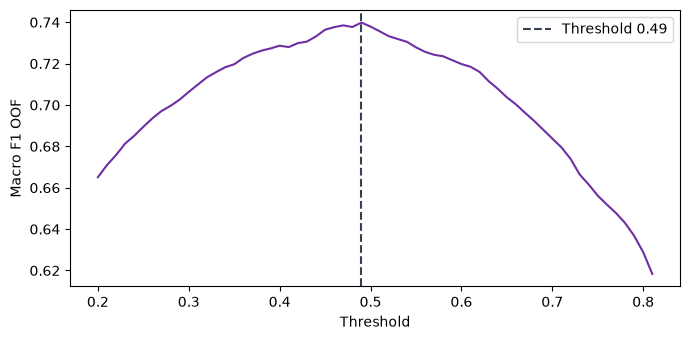

In [33]:
display(ranking.head(12).reset_index(drop=True).round(5))

thresholds = np.round(np.arange(0.20, 0.81, 0.01), 2)
scores = [macro_f1(y, oof_nb >= threshold) for threshold in thresholds]
plt.figure(figsize=(7, 3.5))
plt.plot(thresholds, scores, color='#6d2fa3')
plt.axvline(THRESHOLD, color='#334155', linestyle='--', label=f'Threshold {THRESHOLD:.2f}')
plt.xlabel('Threshold')
plt.ylabel('Macro F1 OOF')
plt.legend()
plt.tight_layout()
plt.show()

Tabel menunjukkan kandidat pada fold yang sama. Skor OOF pemenang adalah skor seleksi parameter.

---

# Comparison with scikit-learn <a name="8"></a>

---

Bandingkan Categorical Naive Bayes from scratch dan CategoricalNB dengan preprocessing, fold, serta alpha yang sama. Baris scikit-learn standar memakai bobot satu. Untuk memverifikasi varian berbobot, terapkan bobot yang sama pada log-likelihood hasil fit scikit-learn.

In [34]:
class SklearnNB:
    def __init__(self, weights=None):
        self.model = CategoricalNB(alpha=SELECTED_ALPHA, min_categories=2)
        self.weights = weights

    def fit(self, X, y):
        self.model.fit(X, y)
        return self

    def predict_proba(self, X):
        if self.weights is None:
            return self.model.predict_proba(X)[:, 1]
        X = np.asarray(X)
        log_prior = self.model.class_log_prior_
        scores = np.broadcast_to(log_prior, (len(X), 2)).copy()
        for column, table in enumerate(self.model.feature_log_prob_):
            scores += self.weights[column] * table[:, X[:, column]].T
        values = np.exp(scores - scores.max(axis=1, keepdims=True))
        return values[:, 1] / values.sum(axis=1)


oof_sk_plain = cross_val_proba(SklearnNB, make_prep, train, y, folds)
oof_sk = cross_val_proba(lambda: SklearnNB(SELECTED_WEIGHTS), make_prep, train, y, folds)
np.testing.assert_allclose(oof_nb, oof_sk, atol=1e-12)
print(f'Selisih maksimum peluang OOF: {np.abs(oof_nb - oof_sk).max():.2e}')

comparison_rows = []
for name, probabilities in (
    ('From scratch berbobot', oof_nb),
    ('scikit-learn standar', oof_sk_plain),
    ('scikit-learn dengan likelihood berbobot', oof_sk),
):
    cutoff, score = best_threshold(y, probabilities)
    std_fold = fold_scores(y, probabilities, folds, cutoff).std()
    comparison_rows.append({'Model': name, 'OOF Macro F1': score, 'Std antar-fold': std_fold,
                            'Threshold': cutoff})
pd.DataFrame(comparison_rows).set_index('Model').round(5)

Selisih maksimum peluang OOF: 5.33e-15


,OOF Macro F1,Std antar-fold,Threshold
Model,,,
From scratch berbobot,0.73984,0.00482,0.49
scikit-learn standar,0.73380,0.00869,0.42
scikit-learn dengan likelihood berbobot,0.73984,0.00482,0.49


---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

Bundle menyimpan preprocessor, model, dan threshold. Jalankan sel definisi kelas sebelum membuka bundle dari kernel baru.

In [35]:
def save_model(model, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, 'wb') as f:
        pickle.dump(model, f)


def load_model(path):
    with open(path, 'rb') as f:
        return pickle.load(f)

In [36]:
prep_final = make_prep().fit(train)
nb_final = NaiveBayes(alpha=SELECTED_ALPHA, weights=SELECTED_WEIGHTS).fit(prep_final.transform(train), y)
print('fitur', len(prep_final.columns_), 'alpha', SELECTED_ALPHA, 'threshold', THRESHOLD)

save_model({'preprocessor': prep_final, 'model': nb_final, 'threshold': THRESHOLD}, CFG.MODEL_PATH)
bundle = load_model(CFG.MODEL_PATH)

fitur 17 alpha 2.0 threshold 0.49


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

CSV `submission_nb_baseline_finetune.csv` disimpan sebagai artefak eksperimen lokal. Preprocessing mengikuti notebook baseline. Macro F1 OOF **0,73984** berasal dari validasi silang internal pada data latih.

In [37]:
X_test = bundle['preprocessor'].transform(test_df)
test_pred = bundle['model'].predict(X_test, threshold=bundle['threshold'])

submission = pd.DataFrame({ID_COL: test_df[ID_COL], TARGET: test_pred})
assert submission[ID_COL].equals(sample[ID_COL])
assert len(submission) == 6_844
CFG.SUB_PATH.parent.mkdir(parents=True, exist_ok=True)
submission.to_csv(CFG.SUB_PATH, index=False)
print('CSV:', CFG.SUB_PATH)
print('SHA-256:', hashlib.sha256(CFG.SUB_PATH.read_bytes()).hexdigest())

print(submission[TARGET].value_counts(normalize=True).round(4))
submission.head()

CSV: output/template_nb/submissions/submission_nb_baseline_finetune.csv
SHA-256: 1624986e7d647efe582399e1baf3ad88b0535b0ff794dfb4db83718d55513163
is_canceled
0    0.6712
1    0.3288
Name: proportion, dtype: float64


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,1
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

Analisis memakai prediksi out-of-fold dari train.

## Confusion Matrix

In [38]:
oof_pred = (oof_nb >= THRESHOLD).astype(int)
print('confusion matrix OOF [[TN, FP], [FN, TP]]')
print(confusion_matrix(y, oof_pred))
print('F1 per kelas [tidak batal, batal]', f1_per_class(y, oof_pred).round(4))

confusion matrix OOF [[TN, FP], [FN, TP]]
[[15113  3252]
 [ 3044  5900]]
F1 per kelas [tidak batal, batal] [0.8276 0.6521]


## Kesalahan per Kelompok

In [39]:
def error_by(values, name):
    frame = pd.DataFrame({name: values, 'error': oof_pred != y})
    return frame.groupby(name, observed=True, dropna=False)['error'].agg(['mean', 'size']).round(3)

In [40]:
error_by(pd.qcut(train['days_before_arrival'], 5, duplicates='drop'), 'days_before_arrival')

,mean,size
days_before_arrival,,
"(-0.001, 11.0]",0.101,5286
"(11.0, 39.0]",0.182,5332
"(39.0, 80.0]",0.216,5186
"(80.0, 151.0]",0.386,5180
"(151.0, 448.0]",0.268,5205
NaN,0.251,1120


In [41]:
error_by(train['special_requests'], 'special_requests')

,mean,size
special_requests,,
0.0,0.254,12678
1.0,0.239,8323
2.0,0.140,3246
3.0,0.000,496
4.0,0.000,60
5.0,0.143,7
NaN,0.254,2499


#### Insights

Perbandingan F1 per kelas dan tingkat kesalahan per kelompok membantu menunjukkan kapan model kesulitan membedakan pembatalan dari pemesanan yang tetap berjalan.

---

# Referensi <a name="references"></a>

- Rumus likelihood tiap kategori dan smoothing pada Categorical Naive Bayes. [Dokumentasi scikit-learn](https://scikit-learn.org/stable/modules/naive_bayes.html#categorical-naive-bayes)
- Pembobotan atribut mengubah kontribusi setiap fitur pada skor kelas. Eksperimen ini menguji bobot dua fitur dengan grid berdasarkan Macro F1 OOF. [Zaidi et al., 2013](https://www.jmlr.org/papers/v14/zaidi13a.html)

---

# Bonus Naive Bayes <a name="12"></a>

Graf Bayesian Network menempatkan `is_canceled` sebagai induk dan 17 fitur baseline sebagai anak. Panah menggambarkan faktorisasi model. Naive Bayes mengasumsikan fitur saling independen setelah kelas diketahui. Graf ini tidak menyatakan hubungan sebab-akibat.

Graf bonus: output/template_nb/figures/bonus_nb_baseline_finetune.png


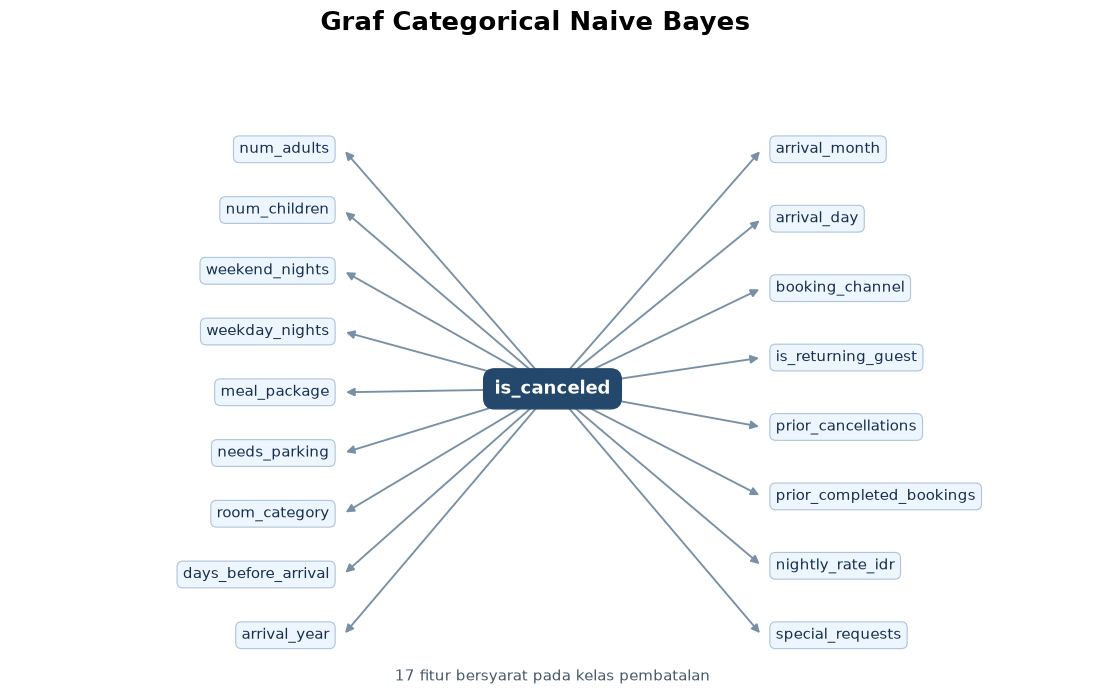

In [42]:
# Buat graf hubungan target dengan fitur yang dipakai model final.
columns = prep_final.columns_
fig, ax = plt.subplots(figsize=(14, 8), facecolor='white')
ax.set(xlim=(0, 14), ylim=(0, 9))
ax.axis('off')
fig.suptitle('Graf Categorical Naive Bayes', fontsize=19, fontweight='bold', y=0.96)

for side, names in enumerate((columns[:9], columns[9:])):
    x_edge = 4.3 if side == 0 else 9.7
    x_label = 4.12 if side == 0 else 9.88
    x_root = 7.0
    for name, y_pos in zip(names, np.linspace(7.9, 0.8, len(names))):
        ax.annotate('', xy=(x_edge, y_pos), xytext=(x_root, 4.4),
                    arrowprops={'arrowstyle': '-|>', 'color': '#7890a6',
                                'lw': 1.35, 'mutation_scale': 12}, zorder=1)
        ax.text(x_label, y_pos, name, ha='right' if side == 0 else 'left',
                va='center', fontsize=10.5, color='#17304d', zorder=2,
                bbox={'boxstyle': 'round,pad=0.4', 'fc': '#edf5ff',
                      'ec': '#afc4da', 'lw': 0.8})

ax.text(7, 4.4, 'is_canceled', ha='center', va='center', fontsize=13,
        fontweight='bold', color='white', zorder=3,
        bbox={'boxstyle': 'round,pad=0.6', 'fc': '#24486c', 'ec': '#24486c'})
ax.text(7, 0.14, '17 fitur bersyarat pada kelas pembatalan',
        ha='center', color='#46596b', fontsize=11)
CFG.BONUS_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(CFG.BONUS_PATH, dpi=160, bbox_inches='tight', facecolor='white')
print('Graf bonus:', CFG.BONUS_PATH)
plt.show()